# From emissions to warming — and the data behind one IPCC figure

### A data story on IPCC AR6 Synthesis Report, Longer Report **Figure 2.1**

The IPCC Sixth Assessment Report (AR6) closed in March 2023 with the *Synthesis Report* (SYR).
Its Longer Report **Figure 2.1** condenses the physical-science story of AR6 into four panels:
greenhouse-gas **emissions** have risen (a), **concentrations** have risen with them (b),
the planet has **warmed** by about 1.1 °C (c), and essentially **all** of that warming is attributable to human influence (d).

This notebook follows the IPCC's own data-management model — **input → intermediate → final** data — to show
where each panel comes from, which Data Distribution Centre (DDC) archive holds it, and how you can reuse it.
Every chart is **redrawn from archived data**; nothing is copied from the published image.

> **How to read this page.** Text explains the provenance; charts are produced live in your browser by a Python kernel
> running in WebAssembly (JupyterLite via *notebook.link*). The CEDA files are **fetched live from `dap.ceda.ac.uk`**
> when the archive is reachable, otherwise the bundled copies are used — a provenance log says which.
> The companion story map `storymap/ipcc_ar6_data_journey.jGIS` travels to the places where the data are made and kept.

## 1 · Start at the figure

**Figure 2.1 — *The causal chain from emissions to resulting warming of the climate system.***
Published at [ipcc.ch/report/ar6/syr/figures/figure-2-1](https://www.[ipcc.ch/report/ar6/syr/figures/figure-2-1](https://ipcc.ch/report/ar6/syr/figures/figure-2-1)).

The caption ends with the IPCC's traceability tag (quoted from the Longer Report, p. 59):

> `{WGI SPM A.2.2, WGI Figure SPM.1, WGI Figure SPM.2, WGI TS2.2, WGI 2.1; WGIII Figure SPM.1, WGIII A.III.II.2.5.1}`

That tag is the map to the data:

| Panel | What it shows | Source in the Working-Group reports |
|---|---|---|
| **(a)** | Global net anthropogenic GHG emissions 1990–2019 by gas (CO₂-FFI, CO₂-LULUCF, CH₄, N₂O, F-gases) | **WGIII Figure SPM.1**, Annex III.II.2.5.1 |
| **(b)** | Annual CO₂, CH₄, N₂O concentrations; each sub-panel's height scaled to the gas's warming effect 1850–1900 → 2010–2019 | **WGI Section 2.1** (Chapter 2 Figures 2.4, 2.5) and the SPM.2(c) warming estimates |
| **(c)** | Global surface temperature anomaly vs 1850–1900, plus the warmest multi-century period of the last 100 000 years | **WGI Figure SPM.1** |
| **(d)** | Warming 1850–1900 → 2010–2019 attributed to total human influence, GHGs, other human drivers, natural drivers, internal variability | **WGI Figure SPM.2**, SPM A.2.2 |

Because the SYR is a synthesis, its figure data are a *re-publication* of Working-Group data. SYR-level records exist only
for panels (c) and (d); for (a) and (b) one goes back to the WGIII and WGI records.

## 1b · How the IPCC manages data: three tiers, five archives

The IPCC Data Distribution Centre (DDC, [ipcc-data.org](https://ipcc-data.org)) is run by **DKRZ** (Germany), **CSIC-IFCA** (Spain),
**CIESIN** (Columbia University, USA) and **MetadataWorks** (UK); **CEDA** (UK) archives the WGI/WGII figure data.

| Tier | Definition | Where it lives (AR6) |
|---|---|---|
| **Input data** | observations, inventories and model simulations the authors started from | CMIP6 subset at **DKRZ** (`IPCC-AR6_CMIP6`, 65 118 datasets, DOIs `10.26050/WDCC/AR6.*`); observations cited to the producing networks; a few *Input data for Figure x.y* records at **CEDA** |
| **Intermediate data** | products created by authors while processing inputs | **DKRZ** `IPCC-DDC_AR6_Supplements`, **CSIC** (Interactive Atlas), chapter-level figure records at **CEDA** |
| **Final data** | the numbers actually plotted in a published figure | WGI/WGII: **CEDA** (`10.5285/…`, CC BY 4.0); WGIII: **IPCC Data Catalogue / MetadataWorks** (`10.48490/…`); SYR: **CIESIN-SEDAC** (`10.7927/…`) |

### Data status for Figure 2.1 at a glance

| Tier → panel | (a) emissions | (b) concentrations | (c) temperature | (d) attribution |
|---|:-:|:-:|:-:|:-:|
| **1** Report (ipcc.ch) | 🔵 | 🔵 | 🔵 | 🔵 |
| **2** Input · DDC at DKRZ (CMIP6) | – | – | 🔵 | 🔵 |
| **2** Input · originating institutions | 🔵 | 🔵 | 🟢 | 🔵 |
| **3** Intermediate · chapter-level records at CEDA | 🟡 | 🟢 | 🟢 | 🟢 |
| **4** Final · Working-Group record | 🟢 | 🟢 | 🟢 | 🟢 |
| **4** Final · SYR record (CIESIN / SEDAC) | 🔴 | 🔴 | 🟡 | 🟡 |

🟢 **available** – copy in this project, loaded live from the archive when online ·
🔵 **online** – published, link only ·
🟡 **partial** – exists but incomplete / not verifiable from here ·
🔴 **missing** – no record · checked 2026-10-13


The next sections walk through each tier; the story map presents the same chain stop by stop.

### Data access: live from CEDA, with a bundled fallback

The cell below defines two helpers used throughout: `load_text()` fetches a file from the CEDA archive
(`https://dap.ceda.ac.uk/badc/ar6_wg1/data/…`, CORS enabled) and falls back to the copy in `data/`;
`read_badc_csv()` parses CEDA's *BADC-CSV* format (metadata header, `data` marker, rows, `end_data`).

In [1]:
import io, os, sys, csv, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

warnings.filterwarnings("ignore")
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "font.size": 10, "axes.titleweight": "bold"})

CEDA_DAP = "https://dap.ceda.ac.uk/badc/ar6_wg1/data"
PREFER_LIVE = True          # set False to force the bundled copies

# local path -> path under CEDA_DAP (all CC BY 4.0; catalogue uuid = DOI suffix in data/PROVENANCE.md)
CEDA = {
    "data/final/wgi_spm1/SPM1_1850-2020_obs.csv":              "spm/spm_01/v20221116/panel_a/SPM1_1850-2020_obs.csv",
    "data/final/wgi_spm1/SPM1_1-2000_recon.csv":               "spm/spm_01/v20221116/panel_a/SPM1_1-2000_recon.csv",
    "data/final/wgi_spm1/spm1_6500_recon.csv":                 "spm/spm_01/v20221116/panel_a/spm1_6500_recon.csv",
    "data/final/wgi_spm1/gmst_changes_model_and_obs.csv":      "spm/spm_01/v20221116/panel_b/gmst_changes_model_and_obs.csv",
    "data/final/wgi_spm2/SPM2a.csv":                           "spm/spm_02/v20210809/panel_a/SPM2a.csv",
    "data/final/wgi_spm2/SPM2b.csv":                           "spm/spm_02/v20210809/panel_b/SPM2b.csv",
    "data/final/wgi_spm2/SPM2c_data.csv":                      "spm/spm_02/v20210809/panel_c/SPM2c_data.csv",
    "data/final/wgi_ch2_fig2_5/Data_Figure_2.5.csv":           "ch_02/ch2_fig05/v20221116/Data_Figure_2.5.csv",
    "data/intermediate/wgi_ch2_fig2_4/fig2_4b_data_v2.csv":    "ch_02/ch2_fig04/v20221219/fig2_4b_data_v2.csv",
    "data/intermediate/wgi_ch2_fig2_4/fig2_4b_2ka_CH4.csv":    "ch_02/ch2_fig04/v20221219/fig2_4_data_Feb24_2021/fig2_4b_2ka_CH4.csv",
    "data/intermediate/wgi_ch2_fig2_11/Figure2_11_panel_a.csv": "ch_02/ch2_fig11/v20220510/Figure2_11_panel_a.csv",
    "data/input/wgi_ch2_fig2_11_input/Figure_2_11c-lower_panel.csv": "ch_02/inputdata_ch2_fig11/v20220428/Figure_2_11c-lower_panel.csv",
    "data/intermediate/wgi_ch3_fig3_8/drivers_observed_warming.csv": "ch_03/ch3_fig08/v20220613/drivers_observed_warming.csv",
    "data/intermediate/wgi_ch7_fig7_6/AR6_ERF_1750-2019.csv":  "ch_07/ch7_fig06/v20220721/AR6_ERF_1750-2019.csv",
    "data/intermediate/wgi_ch7_fig7_8/fig7.8.csv":             "ch_07/ch7_fig08/v20220721/fig7.8.csv",
}
SOURCE_LOG = {}

def _fetch(url, timeout=60):
    '''Return the text at `url`. Inside the WebAssembly kernel use a synchronous XMLHttpRequest via pyjs.'''
    if sys.platform == "emscripten":
        import pyjs
        xhr = pyjs.new(pyjs.js.XMLHttpRequest)
        xhr.open("GET", url, False)
        xhr.send()
        status = xhr.status
        status = int(status if isinstance(status, (int, float)) else pyjs.to_py(status))
        if status != 200:
            raise IOError(f"HTTP {status}")
        text = xhr.responseText
        return text if isinstance(text, str) else str(pyjs.to_py(text))
    import urllib.request
    req = urllib.request.Request(url, headers={"User-Agent": "ipcc-ar6-syr-fig2-1-data-story"})
    with urllib.request.urlopen(req, timeout=timeout) as r:
        return r.read().decode("utf-8", "replace")

def load_text(local):
    '''Text of a data file: live CEDA copy when possible, bundled copy otherwise.'''
    remote = CEDA.get(local)
    if PREFER_LIVE and remote:
        try:
            text = _fetch(f"{CEDA_DAP}/{remote}")
            SOURCE_LOG[local] = "live · dap.ceda.ac.uk"
            return text
        except Exception as e:
            SOURCE_LOG[local] = f"bundled copy (live failed: {type(e).__name__})"
    else:
        SOURCE_LOG[local] = "bundled copy"
    with open(local, encoding="utf-8", errors="replace") as fh:
        return fh.read()

def read_badc_csv(local):
    '''Read a BADC-CSV file -> (metadata dict, DataFrame with named columns, missing values as NaN).'''
    meta, rows, in_data = {}, [], False
    for parts in csv.reader(io.StringIO(load_text(local))):
        parts = [p.strip() for p in parts]
        if not parts:
            continue
        if not in_data:
            if parts[0] == "data":
                in_data = True
                continue
            meta.setdefault(parts[0], []).append(parts[1:])
        else:
            if parts[0] == "end_data":
                break
            rows.append(parts)
    header_idx = rows[0]                                   # first data row = column numbers
    rows = rows[1:]
    ncol = max(i for i, p in enumerate(header_idx) if p != "") + 1
    names = {}
    for key in ("coordinate_variable", "long_name"):      # long_name overrides coordinate_variable
        for ln in meta.get(key, []):
            if ln and ln[0].isdigit() and len(ln) > 1:
                names[int(ln[0])] = ln[1]
    cols = [names.get(i + 1, f"col{i+1}") for i in range(ncol)]
    df = pd.DataFrame([(r + [""] * ncol)[:ncol] for r in rows], columns=cols)
    df = df.apply(pd.to_numeric, errors="coerce") if all(c != "Drivers_warming" for c in cols) else df
    mv = meta.get("missing_value")                        # e.g. [['G', '1.00E+20']]
    if mv and len(mv[0]) > 1 and mv[0][1]:
        try:
            df = df.replace(float(mv[0][1]), np.nan)
        except ValueError:
            pass
    return meta, df

def read_csv(local, **kw):
    return pd.read_csv(io.StringIO(load_text(local)), **kw)

print("helpers ready · platform:", sys.platform, "· live loading:", PREFER_LIVE)

helpers ready · platform: linux · live loading: True


## 2 · Input data — where the raw numbers come from

### Panel (a): emissions inventories 🔵
* **EDGAR v6.0** (EU Joint Research Centre): fossil CO₂, CH₄, N₂O and F-gases by country and sector.
* **CO₂ from land use (LULUCF)**: mean of three bookkeeping models — **BLUE**, **Houghton & Nassikas**, **OSCAR** (Global Carbon Budget).
* Harmonised by the WGIII Chapter 2 team into the dataset of **Minx et al. (2021)**, Zenodo
  [doi:[10.5281/zenodo.6483002](https://doi.org/10.5281/zenodo.6483002)](https://doi.org/10.5281/zenodo.6483002), code at [github.com/mcc-apsis/AR6-Emissions-trends-and-drivers](https://github.com/mcc-apsis/AR6-Emissions-trends-and-drivers).

### Panel (b): atmospheric observations and ice cores 🔵
Global mean mole fractions from **NOAA GML**, **Scripps (Mauna Loa, since 1958)**, **CSIRO** (Cape Grim), **AGAGE**, **UCI**;
before the instrumental era, Antarctic ice cores (**Law Dome, WAIS Divide, EDML**) assessed in WGI Chapter 2 (Figure 2.4).

### Panel (c): temperature records 🟢 and palaeoclimate reconstructions 🔵
* 1850–2020: the **AR6 Chapter 2 assessed mean** of four datasets — HadCRUT5, NOAAGlobalTemp-Interim, Berkeley Earth, Kadow et al. (2020).
  CEDA publishes these four series as an *Input data for Figure 2.11* record
  ([doi:[10.5285/033cd690…](https://doi.org/10.5285/033cd690801741c9bc745b8da55faef4)](https://doi.org/10.5285/033cd690801741c9bc745b8da55faef4)) — plotted below.
* 1–2000 CE: **PAGES 2k Consortium (2019)**; ~6500 years ago: Chapter 2 mid-Holocene assessment.
* Model context: **CMIP6** `historical`+`ssp245` and `hist-nat` ensembles, archived at DKRZ (`IPCC-AR6_CMIP6`).

### Panel (d): detection & attribution inputs 🔵
**HadCRUT4.6** observations; **CMIP6 DAMIP** experiments `hist-GHG`, `hist-aer`, `hist-nat`, `historical`+`ssp245` (Gillett et al. 2021) at DKRZ;
forcing-based estimates from WGI Chapter 7.

Full tables with links: [`data/input/README.md`](data/input/README.md).

### 2a · The four observational datasets behind panel (c)

The CEDA *Input data for Figure 2.11* record holds the annual global surface temperature anomalies (vs 1850–1900) of the four datasets
the authors averaged, with HadCRUT5's confidence limits and the decadal means used in the SPM.

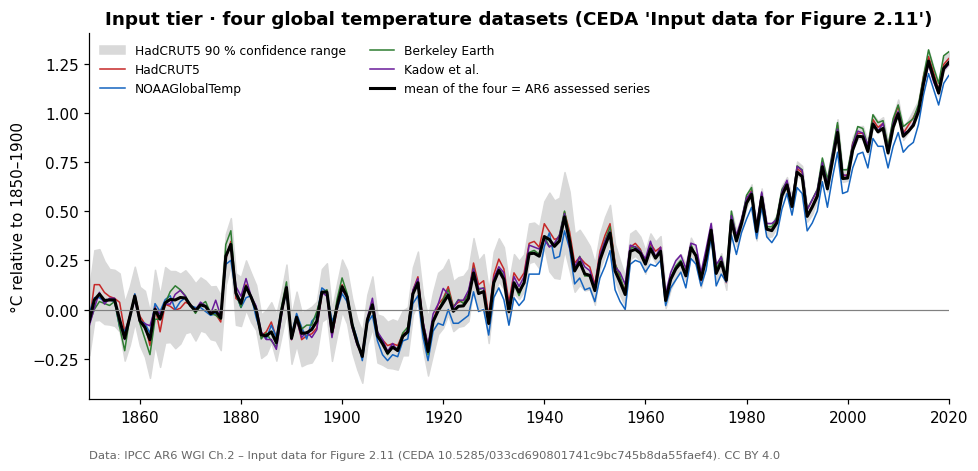

Decadal means (°C vs 1850–1900) as stored in the record:


,HadCRUT5,NOAAGlobalTemp,Berkeley Earth,Kadow et al.
1991-2000,0.67,0.58,0.70,0.68
2001-10,0.91,0.80,0.93,0.90
2011-20,1.12,1.02,1.14,1.09


Loaded from: live · dap.ceda.ac.uk


In [2]:
raw = read_csv("data/input/wgi_ch2_fig2_11_input/Figure_2_11c-lower_panel.csv", index_col=0)
raw.columns = ["HadCRUT5", "NOAAGlobalTemp", "Berkeley Earth", "Kadow et al.", "_", "HadCRUT lower", "HadCRUT upper"]
yr = pd.to_numeric(raw.index, errors="coerce")
four = raw[yr.notna()].copy(); four.index = yr[yr.notna()].astype(int)
decadal = raw[yr.isna() & raw.index.notna()].iloc[:, :4]
datasets = ["HadCRUT5", "NOAAGlobalTemp", "Berkeley Earth", "Kadow et al."]

fig, ax = plt.subplots(figsize=(9, 4.4))
ax.fill_between(four.index, four["HadCRUT lower"], four["HadCRUT upper"], color="0.85", label="HadCRUT5 90 % confidence range")
for c, col in zip(datasets, ["#c62828", "#1565c0", "#2e7d32", "#6a1b9a"]):
    ax.plot(four.index, four[c], lw=1, color=col, label=c)
ax.plot(four.index, four[datasets].mean(axis=1), color="k", lw=2, label="mean of the four = AR6 assessed series")
ax.axhline(0, color="0.5", lw=0.8)
ax.set_xlim(1850, 2020); ax.set_ylabel("°C relative to 1850–1900")
ax.set_title("Input tier · four global temperature datasets (CEDA 'Input data for Figure 2.11')")
ax.legend(frameon=False, fontsize=8, ncol=2, loc="upper left")
ax.text(0, -0.16, "Data: IPCC AR6 WGI Ch.2 – Input data for Figure 2.11 (CEDA 10.5285/033cd690801741c9bc745b8da55faef4). CC BY 4.0",
        transform=ax.transAxes, fontsize=7.5, color="0.4")
plt.tight_layout(); plt.show()

print("Decadal means (°C vs 1850–1900) as stored in the record:")
display(decadal.tail(3).round(2))
print("Loaded from:", SOURCE_LOG["data/input/wgi_ch2_fig2_11_input/Figure_2_11c-lower_panel.csv"])

## 3 · Intermediate data — the processing layer

For many AR6 WGI figures, intermediate products are archived at **DKRZ** (`IPCC-DDC_AR6_Supplements`, e.g. assessed GSAT projections,
doi:[10.26050/WDCC/AR6.IPCC-DDC_AR6_Sup_GSATPr](https://doi.org/10.26050/WDCC/AR6.IPCC-DDC_AR6_Sup_GSATPr)) and at **CEDA**. No record is labelled *intermediate data for Figure 2.1*, but the
processing chain is visible in four **chapter-level CEDA records** (all citable, CC BY 4.0, now bundled and loaded live):

| Panel | Chapter-level record (CEDA, CC BY 4.0) | What it adds to the chain |
|---|---|---|
| (b) | WGI Ch.2 *Data for Figure 2.4* v20221219<br>[10.5285/60eeb3cc…](https://doi.org/10.5285/60eeb3cce51a457cb5ee1c577a0c8674) | ice-core and firn CO₂, CH₄, N₂O 0–1996 CE → the pre-instrumental part of panel (b) |
| (c) | WGI Ch.2 *Data for Figure 2.11* v20220510<br>[10.5285/f3515388…](https://doi.org/10.5285/f3515388768344bfb2be0521f82388be) | AR6 four-dataset mean 1850–2020 (annual), PAGES 2k, land vs ocean |
| (d) | WGI Ch.3 *Data for Figure 3.8* v20220613<br>[10.5285/bf3d0b8a…](https://doi.org/10.5285/bf3d0b8a8c0d4ae19cfd994b6fef4a5c) | assessed ranges per driver **and** the lines of evidence behind them (Ribes, Haustein, Gillett, Ch.7; 13 CMIP6 models) |
| (d), (b) | WGI Ch.7 *Data for Figure 7.6* v20220721<br>[10.5285/0dd364e7…](https://doi.org/10.5285/0dd364e74c254b64bb5fddb5dceed364) | effective radiative forcing 1750–2019 by agent |
| (d), (b) | WGI Ch.7 *Data for Figure 7.8* v20220721<br>[10.5285/5ef11ad1…](https://doi.org/10.5285/5ef11ad195844a59b83393870a5860e1) | forcing → emulator → attributed warming by agent (concentration-based twin of the SPM.2(c) numbers) |

For panel (a) no DDC record exists; the Zenodo workbook (country × sector × gas, GWP100 applied) is itself the processed table.
Details: [`data/intermediate/README.md`](data/intermediate/README.md).

### 3a · Forcing → warming by agent (WGI Chapter 7, Figures 7.6 and 7.8)

Left: effective radiative forcing (ERF) relative to 1750. Right: the global surface air temperature change each agent produced,
from the Chapter 7 two-layer emulator constrained to the assessed climate metrics. These are *concentration-based* estimates;
SPM.2(c) — and the sub-panel heights of Figure 2.1(b) — use the *emission-based* estimates of Chapter 6 (same ERF time series,
but CH₄ emissions are credited with the ozone and stratospheric water vapour they produce, hence 0.5 °C instead of 0.2 °C).

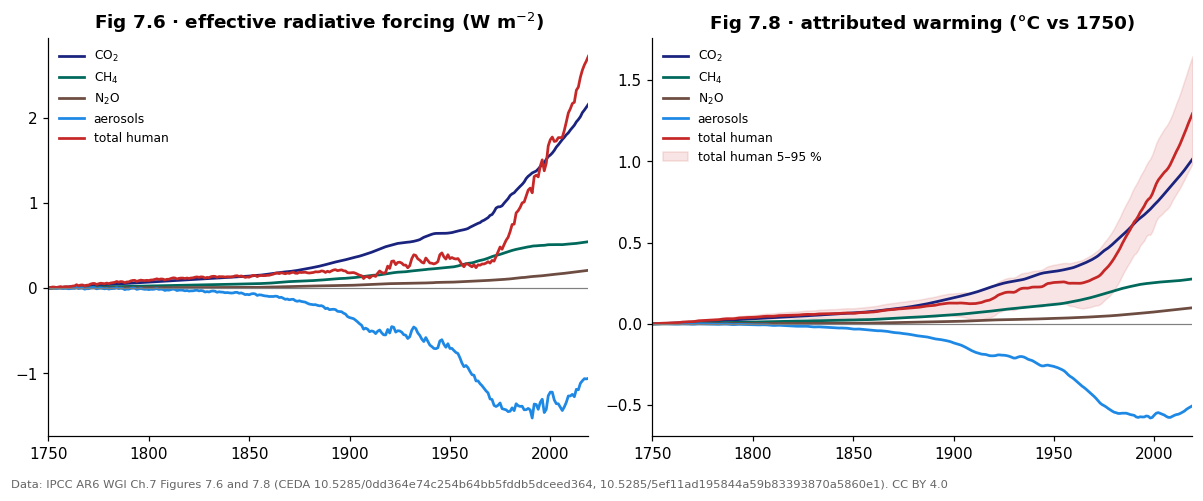

Attributed warming 1850–1900 → 2010–2019 (°C, best estimate): {'CO2': 0.84, 'CH4': 0.23, 'N2O': 0.08, 'aerosol': -0.47, 'anthro': 1.07, 'total': 1.14}
Compare SPM.2(c) emission-based: CO2 0.79, CH4 0.51, N2O 0.09 °C


In [3]:
erf = read_csv("data/intermediate/wgi_ch7_fig7_6/AR6_ERF_1750-2019.csv", index_col="year")
att = read_csv("data/intermediate/wgi_ch7_fig7_8/fig7.8.csv", index_col="year")

agents = [("co2", "CO2", "CO$_2$", "#1a237e"), ("ch4", "CH4", "CH$_4$", "#00695c"), ("n2o", "N2O", "N$_2$O", "#6d4c41"),
          ("aerosol", "aerosol", "aerosols", "#1e88e5"), ("total_anthropogenic", "anthro", "total human", "#c62828")]

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4.4))
for ecol, acol, label, colr in agents:
    ax1.plot(erf.index, erf[ecol], color=colr, lw=1.8, label=label)
    ax2.plot(att.index, att[f"{acol}_best"], color=colr, lw=1.8, label=label)
ax2.fill_between(att.index, att["anthro_p05"], att["anthro_p95"], color="#c62828", alpha=0.12, label="total human 5–95 %")
for ax in (ax1, ax2):
    ax.axhline(0, color="0.5", lw=0.8); ax.set_xlim(1750, 2019); ax.legend(frameon=False, fontsize=8, loc="upper left")
ax1.set_title("Fig 7.6 · effective radiative forcing (W m$^{-2}$)")
ax2.set_title("Fig 7.8 · attributed warming (°C vs 1750)")
fig.text(0.01, -0.02, "Data: IPCC AR6 WGI Ch.7 Figures 7.6 and 7.8 (CEDA 10.5285/0dd364e74c254b64bb5fddb5dceed364, 10.5285/5ef11ad195844a59b83393870a5860e1). CC BY 4.0",
         fontsize=7.5, color="0.4")
plt.tight_layout(); plt.show()

a1019 = att.loc[2010:2019].mean() - att.loc[1850:1900].mean()
print("Attributed warming 1850–1900 → 2010–2019 (°C, best estimate):",
      {k: round(float(a1019[f"{k}_best"]), 2) for k in ["CO2", "CH4", "N2O", "aerosol", "anthro", "total"]})
print("Compare SPM.2(c) emission-based: CO2 0.79, CH4 0.51, N2O 0.09 °C")

### 3b · Lines of evidence behind panel (d) (WGI Chapter 3, Figure 3.8)

The assessed *likely* range for each driver (grey band) was derived from several attribution studies (coloured markers) and the
spread of individual CMIP6 models (small dots). SPM.2(b) — and therefore SYR panel (d) — shows only the assessed range.

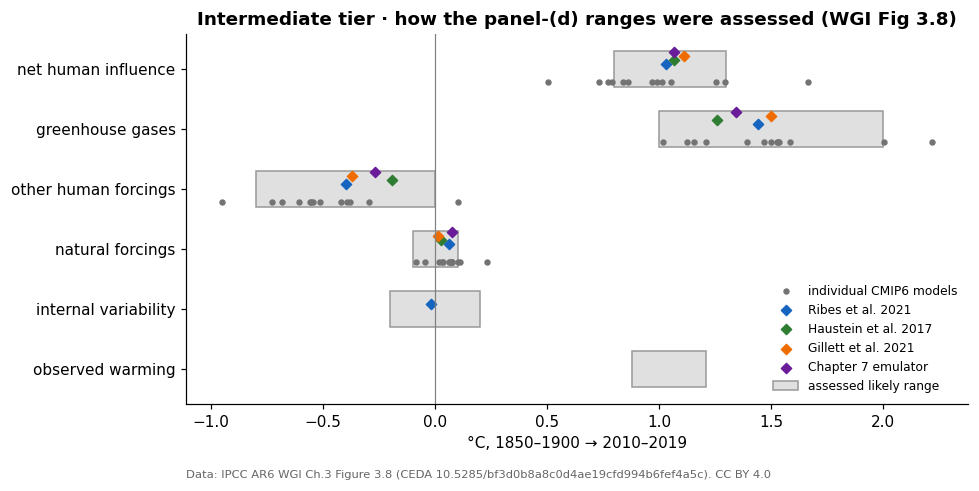

In [4]:
_, drv = read_badc_csv("data/intermediate/wgi_ch3_fig3_8/drivers_observed_warming.csv")
drv = drv.set_index("Drivers_warming").apply(pd.to_numeric, errors="coerce").replace(1e20, np.nan)
rows = ["net human influence", "greenhouse gases", "other human forcings", "natural forcings", "internal variability", "observed warming"]
studies = [("ribes", "Ribes et al. 2021", "#1565c0"), ("haustein", "Haustein et al. 2017", "#2e7d32"),
           ("gillett", "Gillett et al. 2021", "#ef6c00"), ("chapter7", "Chapter 7 emulator", "#6a1b9a")]
model_cols = [c for c in drv.columns if c.endswith("_mean")]

fig, ax = plt.subplots(figsize=(9, 4.6))
for i, r in enumerate(rows):
    lo, hi = drv.loc[r, "min_range_shading"], drv.loc[r, "max_range_shading"]
    ax.barh(i, hi - lo, left=lo, height=0.6, color="0.88", edgecolor="0.6", label="assessed likely range" if i == 0 else None)
    ax.scatter(drv.loc[r, model_cols].dropna(), [i + 0.22] * drv.loc[r, model_cols].notna().sum(), s=10, color="0.45",
               label="individual CMIP6 models" if i == 1 else None)
    for j, (key, lab, colr) in enumerate(studies):
        m = next((c for c in drv.columns if c.startswith(f"mean_{key}")), None)
        if m and pd.notna(drv.loc[r, m]):
            ax.scatter(drv.loc[r, m], i - 0.08 - 0.07 * j, marker="D", s=22, color=colr, label=lab if i == 1 else None)
ax.axvline(0, color="0.5", lw=0.8)
ax.set_yticks(range(len(rows))); ax.set_yticklabels(rows); ax.invert_yaxis()
ax.set_xlabel("°C, 1850–1900 → 2010–2019")
ax.set_title("Intermediate tier · how the panel-(d) ranges were assessed (WGI Fig 3.8)")
ax.legend(frameon=False, fontsize=8, loc="lower right")
ax.text(0, -0.2, "Data: IPCC AR6 WGI Ch.3 Figure 3.8 (CEDA 10.5285/bf3d0b8a8c0d4ae19cfd994b6fef4a5c). CC BY 4.0",
        transform=ax.transAxes, fontsize=7.5, color="0.4")
plt.tight_layout(); plt.show()

## 4 · Final data — the records you can download today

Folders in the last column are under `data/final/`; "live" means the notebook reads the file from the CEDA archive when online.

| Panel | Record | DOI | Host · licence | In this project |
|---|---|---|---|---|
| (a) | WGIII *Data for Figure SPM.1* (Lamb et al.) | [10.48490/vfxm-tm28](https://doi.org/10.48490/vfxm-tm28) | IPCC Data Catalogue · per record | rebuilt from the Zenodo source → `wgiii_spm1/` |
| (b) | WGI *Data for Figure 2.5* v20221116 (Hall) | [10.5285/c6f19b27…](https://doi.org/10.5285/c6f19b27f8e74e98968c17c8e1f74c60) | CEDA · CC BY 4.0 | `wgi_ch2_fig2_5/` + live |
| (c) | WGI *Data for Figure SPM.1* v20221116 (Gillett, Kaufman, Neukom) | [10.5285/0b275905…](https://doi.org/10.5285/0b2759059ad6474098e40dad73e0a8ec) | CEDA · CC BY 4.0 | `wgi_spm1/` + live |
| (c) | SYR LR *Figure 2.1 (c)* v1.0.0 | [10.7927/nq55-cr83](https://doi.org/10.7927/nq55-cr83) | CIESIN / SEDAC · see record | **to add** – Excel, browser-only (`syr_fig2_1/`) |
| (d) | WGI *Data for Figure SPM.2* v20210809 (Gillett, Thorne, Trewin, Szopa …) | [10.5285/c1eb6dad…](https://doi.org/10.5285/c1eb6dad1598427f8f9f3eae346ece2f) | CEDA · CC BY 4.0 | `wgi_spm2/` + live |
| (d) | SYR LR *Figure 2.1 (d)* v1.0.0 | [10.7927/b38b-zp83](https://doi.org/10.7927/b38b-zp83) | CIESIN / SEDAC · see record | **to add** |

All CEDA records were re-checked against the catalogue on 2026-10-13: publication state *citable* / *published*, every DOI resolves,
bundled copies byte-identical to the archive. Below, each panel is rebuilt from these files.

### 4a · Panel (a) — Global net anthropogenic GHG emissions, 1990–2019

Rebuilt from the Minx et al. (2021) workbook (the input to WGIII Figure SPM.1): global totals by gas in Gt CO₂-eq yr⁻¹ using AR6 GWP100,
CO₂-LULUCF as the three-model mean. WGIII reported **59 ± 6.6 Gt CO₂-eq in 2019**, 12 % above 2010 and 54 % above 1990.

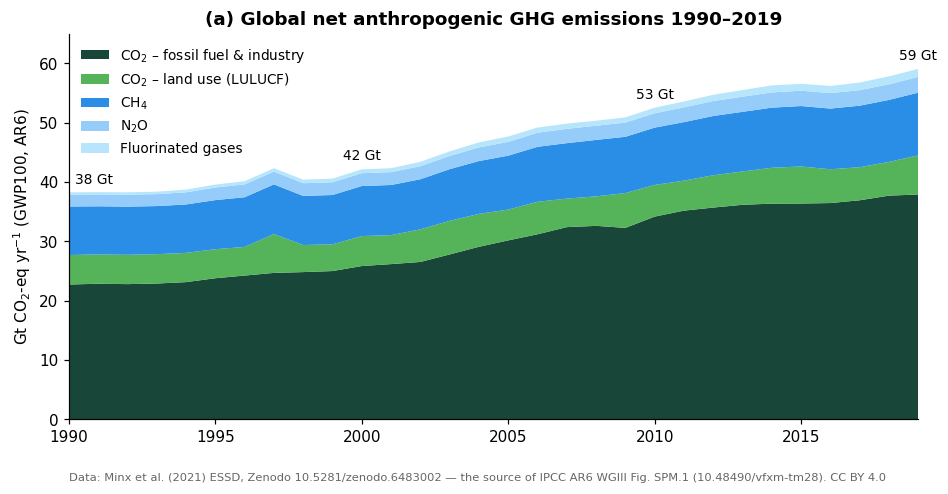

2019 total: 59.1 Gt CO2-eq  |  change vs 1990: +54%  |  vs 2010: +12%
2019 shares (%): {'CO2_FFI': 64.2, 'CO2_LULUCF': 11.2, 'CH4': 17.9, 'N2O': 4.5, 'F_gases': 2.3}


In [5]:
em = pd.read_csv("data/final/wgiii_spm1/global_ghg_emissions_by_gas_1970-2019.csv", comment="#", index_col="year")
em = em.loc[1990:2019]

order  = ["CO2_FFI", "CO2_LULUCF", "CH4", "N2O", "F_gases"]
labels = {"CO2_FFI": "CO$_2$ – fossil fuel & industry", "CO2_LULUCF": "CO$_2$ – land use (LULUCF)",
          "CH4": "CH$_4$", "N2O": "N$_2$O", "F_gases": "Fluorinated gases"}
colors = {"CO2_FFI": "#0b3d2e", "CO2_LULUCF": "#4caf50", "CH4": "#1e88e5", "N2O": "#90caf9", "F_gases": "#b3e5fc"}

fig, ax = plt.subplots(figsize=(9, 4.6))
ax.stackplot(em.index, [em[c] for c in order], labels=[labels[c] for c in order],
             colors=[colors[c] for c in order], alpha=0.95)
tot = em["GHG_total"]
for yr in (1990, 2000, 2010, 2019):
    ax.annotate(f"{tot[yr]:.0f} Gt", (yr, tot[yr]), textcoords="offset points", xytext=(4 if yr == 1990 else 0, 6),
                ha="left" if yr == 1990 else "center", fontsize=9)
ax.set_xlim(1990, 2019); ax.set_ylim(0, 65)
ax.set_ylabel("Gt CO$_2$-eq yr$^{-1}$ (GWP100, AR6)")
ax.set_title("(a) Global net anthropogenic GHG emissions 1990–2019")
ax.legend(loc="upper left", frameon=False, fontsize=9)
ax.text(0, -0.16, "Data: Minx et al. (2021) ESSD, Zenodo 10.5281/zenodo.6483002 — the source of IPCC AR6 WGIII Fig. SPM.1 (10.48490/vfxm-tm28). CC BY 4.0",
        transform=ax.transAxes, fontsize=7.5, color="0.4")
plt.tight_layout(); plt.show()

share = (em.loc[2019, order] / tot[2019] * 100).round(1)
print("2019 total: {:.1f} Gt CO2-eq  |  change vs 1990: {:+.0f}%  |  vs 2010: {:+.0f}%".format(
      tot[2019], (tot[2019]/tot[1990]-1)*100, (tot[2019]/tot[2010]-1)*100))
print("2019 shares (%):", share.to_dict())

### 4b · Panel (b) — Atmospheric concentrations of CO₂, CH₄ and N₂O, 1850–2019

Two CEDA records are joined: the **ice-core and firn records** of WGI Figure 2.4 (the Chapter 2 CO₂ composite to 1946, Law Dome CH₄ and N₂O,
and the Law Dome DE08 methane record of Rubino et al. 2019 to 1980) carry the series from 1850 towards the instrumental era, and the
**network means** of WGI Figure 2.5 (NOAA GML, extended backwards with Scripps CO₂ from 1958 and UCI CH₄ from 1978) carry it to 2019.
As in the SYR figure, **each sub-panel's height is scaled to the gas's assessed warming contribution** (1850–1900 → 2010–2019) from SPM.2(c):
CO₂ ≈ 0.79 °C, CH₄ ≈ 0.51 °C, N₂O ≈ 0.09 °C. One real gap remains in the archived records: CO₂ between the end of the
Chapter 2 ice-core composite (1946) and the first Scripps year (1958). It is drawn as a dotted grey connector, not as data; the assessed annual series that
bridges it is published in WGI Annex III (Table AIII.1a), which is not part of the CEDA figure-data archive.

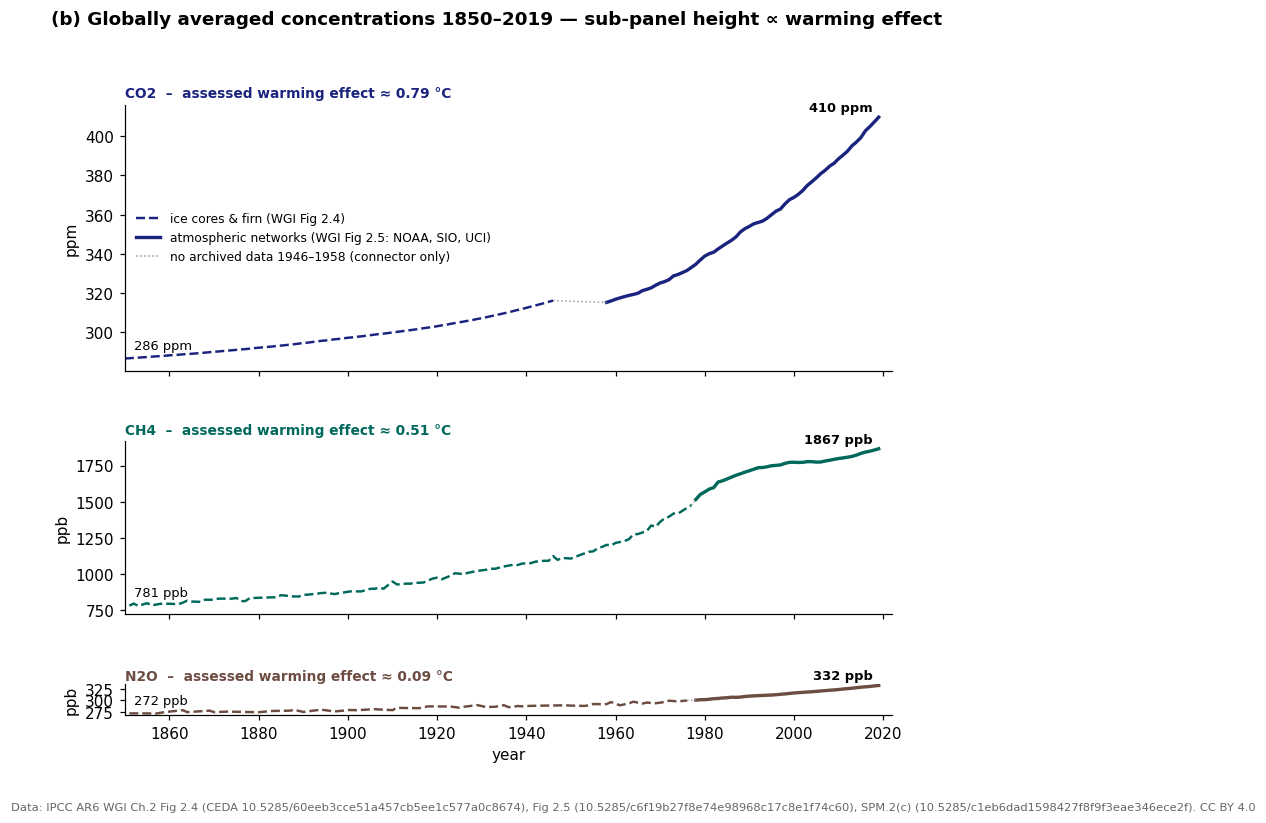

CO2: 1850 ≈ 286.4 ppm (ice core)  →  2019 = 409.8 ppm (NOAA)   ×1.43   | last ice/firn year 1946, first network year 1958
CH4: 1850 ≈ 780.6 ppb (ice core)  →  2019 = 1866.5 ppb (NOAA)   ×2.39   | last ice/firn year 1980, first network year 1978
N2O: 1850 ≈ 272.0 ppb (ice core)  →  2019 = 331.9 ppb (NOAA)   ×1.22   | last ice/firn year 1996, first network year 1978


In [6]:
conc = read_csv("data/final/wgi_ch2_fig2_5/Data_Figure_2.5.csv", skiprows=3)      # 3 comment lines, one of them quoted
_, ice = read_badc_csv("data/intermediate/wgi_ch2_fig2_4/fig2_4b_data_v2.csv")
drivers = read_csv("data/final/wgi_spm2/SPM2c_data.csv").set_index("Driver")
eff = {"CO2": drivers.loc["Carbon dioxide (CO_2)", "total GSAT effect"],
       "CH4": drivers.loc["Methane (CH_4)", "total GSAT effect"],
       "N2O": drivers.loc["Nitrous oxide (N_2O)", "total GSAT effect"]}

def annual(df, xcol, ycol):
    d = df[[xcol, ycol]].dropna()
    return d.groupby(np.floor(d[xcol]).astype(int))[ycol].mean()   # calendar-year means

# NOAA global means, extended backwards with Scripps (CO2, 1958–) and UCI (CH4, 1978–) where NOAA has no value
modern = {"CO2": annual(conc, "NOAA_CO2_xdate", "NOAA_CO2").combine_first(annual(conc, "SIO_CO2_xdate", "SIO_CO2")),
          "CH4": annual(conc, "NOAA_CH4_xdate", "NOAA_CH4").combine_first(annual(conc, "UCI_CH4_xdate", "UCI_CH4")),
          "N2O": annual(conc, "NOAA_N2O_xdate", "NOAA_N2O")}
# Law Dome DE08 firn/ice CH4 (Rubino et al. 2019), 1950–1980: block in columns 22–23 of the Figure 2.4b workbook export
_rows = list(csv.reader(io.StringIO(load_text("data/intermediate/wgi_ch2_fig2_4/fig2_4b_2ka_CH4.csv"))))
de08 = pd.DataFrame([(float(r[21]), float(r[22])) for r in _rows if len(r) > 22 and r[21].strip().replace(".", "", 1).isdigit()],
                    columns=["year", "CH4"])
de08 = de08.groupby(de08["year"].astype(int))["CH4"].mean()

# Chapter 2 CO2 composite (to 1946); CH4: Law Dome record extended by DE08 (to 1980); N2O: Law Dome (to 1996)
icecore = {"CO2": annual(ice, "CO2 composite age", "CO2 composite"),            # Chapter 2 composite, ends 1946
           "CH4": annual(ice, "Law Dome core CH4 age", "Law Dome core CH4").combine_first(de08),
           "N2O": annual(ice, "Law Dome core N2O age", "Law Dome core N2O")}
units = {"CO2": "ppm", "CH4": "ppb", "N2O": "ppb"}
palette = {"CO2": "#1a237e", "CH4": "#00695c", "N2O": "#6d4c41"}

fig, axes = plt.subplots(3, 1, figsize=(9, 7.2), sharex=True,
                         gridspec_kw={"height_ratios": [eff["CO2"], eff["CH4"], eff["N2O"]], "hspace": 0.45})
summary = {}
for ax, gas in zip(axes, ["CO2", "CH4", "N2O"]):
    first_modern = modern[gas].index.min()
    core = icecore[gas].loc[1850:first_modern]
    ax.plot(core.index, core.values, color=palette[gas], lw=1.6, ls="--", label="ice cores & firn (WGI Fig 2.4)")
    ax.plot(modern[gas].index, modern[gas].values, color=palette[gas], lw=2.2, label="atmospheric networks (WGI Fig 2.5: NOAA, SIO, UCI)")
    if core.index.max() < first_modern:                      # real gap in the archived records -> dotted connector, not data
        ax.plot([core.index.max(), first_modern], [core.iloc[-1], modern[gas].iloc[0]], color="0.6", lw=1, ls=":",
                label=f"no archived data {core.index.max()}–{first_modern} (connector only)")
    v1850 = icecore[gas].loc[1840:1860].mean(); v2019 = modern[gas].loc[2019]
    summary[gas] = (v1850, v2019)
    ax.annotate(f"{v1850:.0f} {units[gas]}", (1850, v1850), textcoords="offset points", xytext=(6, 6), fontsize=8.5)
    ax.annotate(f"{v2019:.0f} {units[gas]}", (2019, v2019), textcoords="offset points", xytext=(-4, 4), ha="right", fontsize=8.5, fontweight="bold")
    ax.set_ylabel(units[gas])
    ax.text(0.0, 1.02, f"{gas}  –  assessed warming effect ≈ {eff[gas]:.2f} °C", transform=ax.transAxes,
            fontsize=9, fontweight="bold", color=palette[gas], va="bottom")
    ax.set_xlim(1850, 2022)
axes[0].legend(frameon=False, fontsize=8, loc="center left")
fig.suptitle("(b) Globally averaged concentrations 1850–2019 — sub-panel height ∝ warming effect", fontweight="bold", y=1.0)
axes[-1].set_xlabel("year")
fig.text(0.01, -0.01, "Data: IPCC AR6 WGI Ch.2 Fig 2.4 (CEDA 10.5285/60eeb3cce51a457cb5ee1c577a0c8674), Fig 2.5 (10.5285/c6f19b27f8e74e98968c17c8e1f74c60), SPM.2(c) (10.5285/c1eb6dad1598427f8f9f3eae346ece2f). CC BY 4.0",
         fontsize=7.5, color="0.4")
plt.tight_layout(); plt.show()

for gas, (a, b) in summary.items():
    print(f"{gas}: 1850 ≈ {a:.1f} {units[gas]} (ice core)  →  2019 = {b:.1f} {units[gas]} (NOAA)   ×{b/a:.2f}"
          f"   | last ice/firn year {icecore[gas].index.max()}, first network year {modern[gas].index.min()}")

### 4c · Panel (c) — Global surface temperature change since 1850–1900

From the CEDA record for WGI Figure SPM.1: the annual observed series (Chapter 2 assessed mean) and the decadally smoothed curve,
with the assessed temperature of the **warmest multi-century period in at least the last 100 000 years (~6500 years ago)** shown as a bar.
The chapter-level annual series (Figure 2.11) is overlaid to show that SPM and chapter publish the same numbers.
The SYR records this panel separately as *SYR LR Figure 2.1 (c)* (doi:[10.7927/nq55-cr83](https://doi.org/10.7927/nq55-cr83)).

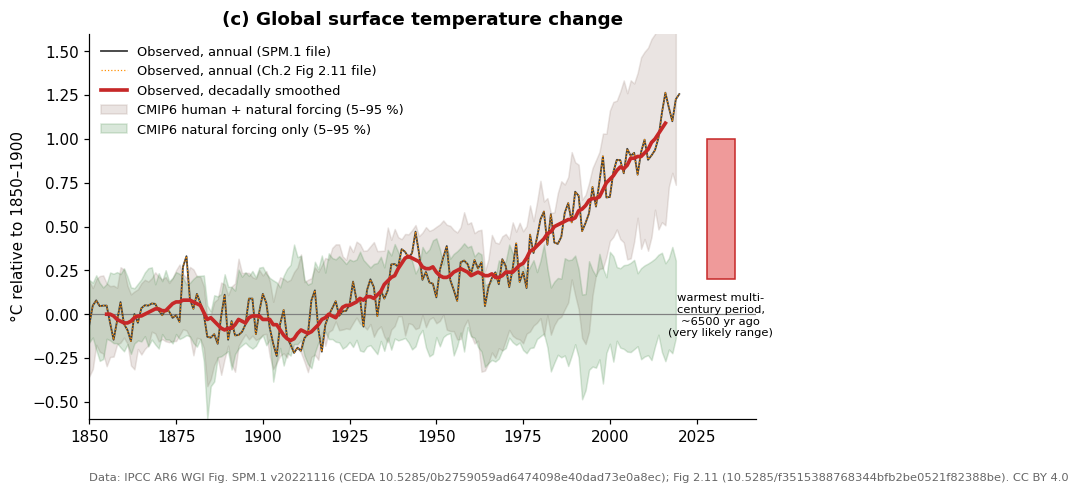

2011–2020 mean observed anomaly: 1.09 °C (SPM.1 file) / 1.09 °C (Fig 2.11 file)
Mid-Holocene very likely range: 0.2–1.0 °C


In [7]:
_, gmst = read_badc_csv("data/final/wgi_spm1/gmst_changes_model_and_obs.csv")
_, obs_dec = read_badc_csv("data/final/wgi_spm1/SPM1_1850-2020_obs.csv")
_, holo = read_badc_csv("data/final/wgi_spm1/spm1_6500_recon.csv")
gmst = gmst.set_index("Year").sort_index()
obs_dec = obs_dec.set_index("Year").sort_index()
holo_lo, holo_hi = holo.iloc[0, 1], holo.iloc[0, 2]
ch2 = read_csv("data/intermediate/wgi_ch2_fig2_11/Figure2_11_panel_a.csv", skiprows=1, usecols=[0, 1], index_col=0).iloc[:, 0].dropna().sort_index()

fig, ax = plt.subplots(figsize=(9, 4.6))
ax.axhline(0, color="0.5", lw=0.8)
ax.plot(gmst.index, gmst["gsta_black_obs"], color="0.25", lw=1.2, label="Observed, annual (SPM.1 file)")
ax.plot(ch2.index, ch2.values, color="#ff8f00", lw=0.8, ls=":", label="Observed, annual (Ch.2 Fig 2.11 file)")
ax.plot(obs_dec.index, obs_dec["Temperature"], color="#c62828", lw=2.4, label="Observed, decadally smoothed")
ax.fill_between(gmst.index, gmst["gsta_brown_shading_bottom_hist_ssp245"], gmst["gsta_brown_shading_top_hist_ssp245"],
                color="#8d6e63", alpha=0.18, label="CMIP6 human + natural forcing (5–95 %)")
ax.fill_between(gmst.index, gmst["gsta_green_shading_bottom_hist_nat"], gmst["gsta_green_shading_top_hist_nat"],
                color="#2e7d32", alpha=0.18, label="CMIP6 natural forcing only (5–95 %)")
ax.bar(2032, holo_hi - holo_lo, bottom=holo_lo, width=8, color="#ef9a9a", edgecolor="#c62828")
ax.text(2032, holo_lo - 0.08, "warmest multi-\ncentury period,\n~6500 yr ago\n(very likely range)", ha="center", va="top", fontsize=7.5)
ax.set_xlim(1850, 2042); ax.set_ylim(-0.6, 1.6)
ax.set_ylabel("°C relative to 1850–1900")
ax.set_title("(c) Global surface temperature change")
ax.legend(loc="upper left", frameon=False, fontsize=8.5)
ax.text(0, -0.16, "Data: IPCC AR6 WGI Fig. SPM.1 v20221116 (CEDA 10.5285/0b2759059ad6474098e40dad73e0a8ec); Fig 2.11 (10.5285/f3515388768344bfb2be0521f82388be). CC BY 4.0",
        transform=ax.transAxes, fontsize=7.5, color="0.4")
plt.tight_layout(); plt.show()

print("2011–2020 mean observed anomaly: {:.2f} °C (SPM.1 file) / {:.2f} °C (Fig 2.11 file)".format(
      gmst.loc[2011:2020, "gsta_black_obs"].mean(), ch2.loc[2011:2020].mean()))
print("Mid-Holocene very likely range: {:.1f}–{:.1f} °C".format(holo_lo, holo_hi))

### 4d · Panel (d) — Humans are responsible

From the CEDA record for WGI Figure SPM.2 panel (b): warming 1850–1900 → 2010–2019 observed (HadCRUT4.6) and attributed to each driver
from CMIP6 DAMIP simulations. Bars are the best estimate (total human influence) or mid-point of the likely range; whiskers are the **likely** range
— the same ranges whose derivation is shown in section 3b.
The SYR records this panel separately as *SYR LR Figure 2.1 (d)* (doi:[10.7927/b38b-zp83](https://doi.org/10.7927/b38b-zp83)).

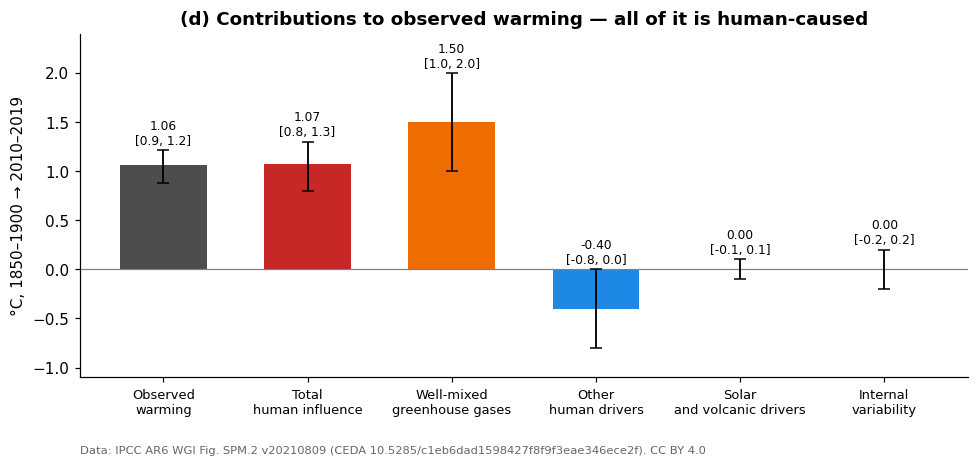

In [8]:
spm2a = read_csv("data/final/wgi_spm2/SPM2a.csv", index_col=0).iloc[:, 0]
spm2b = read_csv("data/final/wgi_spm2/SPM2b.csv", index_col=0)
spm2b.columns = [c.strip() for c in spm2b.columns]
spm2b.index = [i.strip() for i in spm2b.index]

cats = ["Observed warming", "Total human influence", "Well-mixed greenhouse gases",
        "Other human drivers", "Solar and volcanic drivers", "Internal variability"]
centre = [spm2a["Mean/Centre"]] + [spm2b.loc["Mean/Centre", c] for c in cats[1:]]
lo     = [spm2a["Bottom"]]      + [spm2b.loc["Bottom", c]      for c in cats[1:]]
hi     = [spm2a["Top"]]         + [spm2b.loc["Top", c]         for c in cats[1:]]
cols = ["0.3", "#c62828", "#ef6c00", "#1e88e5", "#43a047", "#8e24aa"]

fig, ax = plt.subplots(figsize=(9, 4.4))
ax.axhline(0, color="0.5", lw=0.8)
ax.bar(range(6), centre, color=cols, width=0.6)
ax.errorbar(range(6), centre, yerr=[np.array(centre) - np.array(lo), np.array(hi) - np.array(centre)],
            fmt="none", ecolor="k", capsize=4, lw=1.2)
for i, (c, l, h) in enumerate(zip(centre, lo, hi)):
    ax.text(i, h + 0.06, f"{c:.2f}\n[{l:.1f}, {h:.1f}]", ha="center", fontsize=8)
ax.set_xticks(range(6)); ax.set_xticklabels([c.replace(" ", "\n", 1) for c in cats], fontsize=8.5)
ax.set_ylim(-1.1, 2.4); ax.set_ylabel("°C, 1850–1900 → 2010–2019")
ax.set_title("(d) Contributions to observed warming — all of it is human-caused")
ax.text(0, -0.22, "Data: IPCC AR6 WGI Fig. SPM.2 v20210809 (CEDA 10.5285/c1eb6dad1598427f8f9f3eae346ece2f). CC BY 4.0",
        transform=ax.transAxes, fontsize=7.5, color="0.4")
plt.tight_layout(); plt.show()

### 4e · The whole chain in one view

Putting the four redrawn panels together reproduces the logic of SYR Figure 2.1 from open data alone.

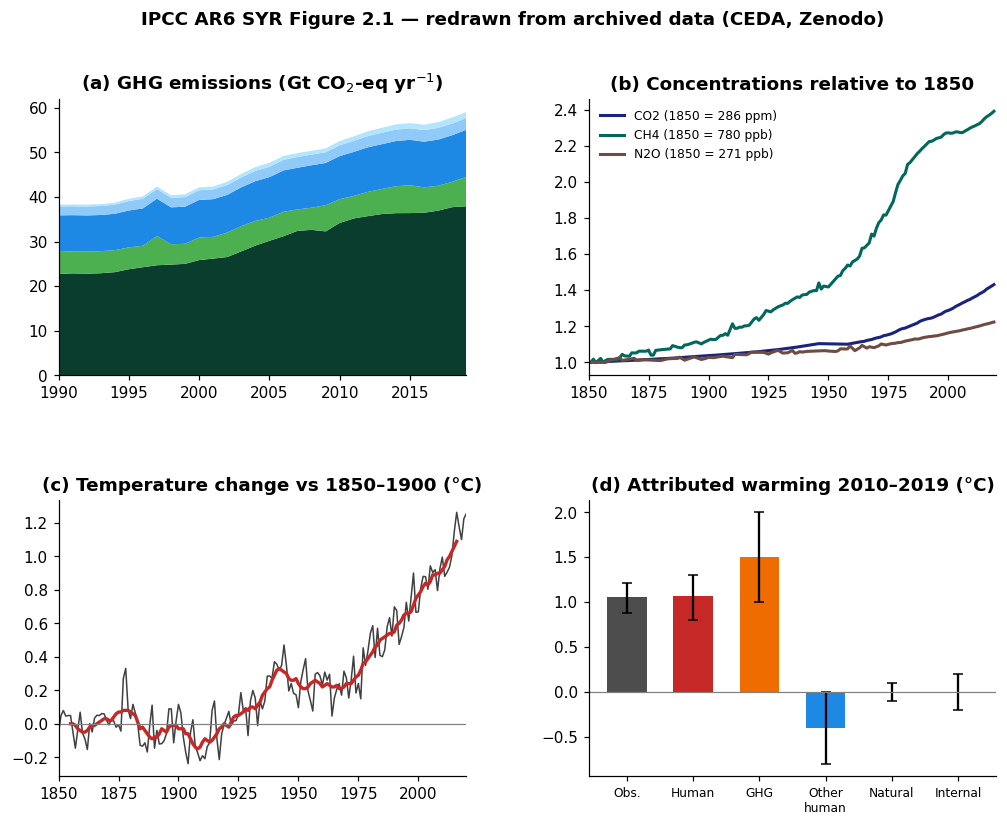

In [9]:
fig = plt.figure(figsize=(11, 8))
gs = fig.add_gridspec(2, 2, hspace=0.45, wspace=0.3)

ax = fig.add_subplot(gs[0, 0])
ax.stackplot(em.index, [em[c] for c in order], colors=[colors[c] for c in order])
ax.set_title("(a) GHG emissions (Gt CO$_2$-eq yr$^{-1}$)"); ax.set_xlim(1990, 2019)

ax = fig.add_subplot(gs[0, 1])
for gas in ["CO2", "CH4", "N2O"]:
    s = pd.concat([icecore[gas].loc[1850:modern[gas].index.min() - 1], modern[gas]])
    ax.plot(s.index, s / s.iloc[0], color=palette[gas], lw=2, label=f"{gas} (1850 = {s.iloc[0]:.0f} {units[gas]})")
ax.set_title("(b) Concentrations relative to 1850"); ax.legend(frameon=False, fontsize=8); ax.set_xlim(1850, 2020)

ax = fig.add_subplot(gs[1, 0])
ax.plot(gmst.index, gmst["gsta_black_obs"], color="0.25", lw=1)
ax.plot(obs_dec.index, obs_dec["Temperature"], color="#c62828", lw=2.2)
ax.axhline(0, color="0.5", lw=0.8); ax.set_title("(c) Temperature change vs 1850–1900 (°C)"); ax.set_xlim(1850, 2020)

ax = fig.add_subplot(gs[1, 1])
ax.bar(range(6), centre, color=cols, width=0.6)
ax.errorbar(range(6), centre, yerr=[np.array(centre) - np.array(lo), np.array(hi) - np.array(centre)], fmt="none", ecolor="k", capsize=3)
ax.axhline(0, color="0.5", lw=0.8)
ax.set_xticks(range(6)); ax.set_xticklabels(["Obs.", "Human", "GHG", "Other\nhuman", "Natural", "Internal"], fontsize=8)
ax.set_title("(d) Attributed warming 2010–2019 (°C)")

fig.suptitle("IPCC AR6 SYR Figure 2.1 — redrawn from archived data (CEDA, Zenodo)", fontweight="bold")
plt.show()

### 4f · Provenance log of this run

Which copy of each CEDA file was actually used — the live archive or the bundled fallback.

In [10]:
from IPython.display import HTML
rows_html = []
for f, src in SOURCE_LOG.items():
    remote = CEDA.get(f)
    live = f'<a href="{CEDA_DAP}/{remote}" target="_blank">{remote.rsplit("/", 1)[-1]}</a>' if remote else "—"
    rows_html.append(f"<tr><td>{os.path.basename(f)}</td><td>{os.path.dirname(f).replace('data/', '')}</td>"
                     f"<td>{src}</td><td>{live}</td></tr>")
display(HTML('<table style="font-size:0.85em;text-align:left;word-break:break-word">'
             '<thead><tr><th>file</th><th>folder (under data/)</th><th>loaded from</th><th>live copy at CEDA</th></tr></thead>'
             '<tbody>' + "".join(rows_html) + '</tbody></table>'))
n_live = sum(v.startswith("live") for v in SOURCE_LOG.values())
print(f"{n_live} of {len(SOURCE_LOG)} CEDA files used by this notebook were loaded live from dap.ceda.ac.uk; the rest from data/")

file,folder (under data/),loaded from,live copy at CEDA
Figure_2_11c-lower_panel.csv,input/wgi_ch2_fig2_11_input,live · dap.ceda.ac.uk,Figure_2_11c-lower_panel.csv
AR6_ERF_1750-2019.csv,intermediate/wgi_ch7_fig7_6,live · dap.ceda.ac.uk,AR6_ERF_1750-2019.csv
fig7.8.csv,intermediate/wgi_ch7_fig7_8,live · dap.ceda.ac.uk,fig7.8.csv
drivers_observed_warming.csv,intermediate/wgi_ch3_fig3_8,live · dap.ceda.ac.uk,drivers_observed_warming.csv
Data_Figure_2.5.csv,final/wgi_ch2_fig2_5,live · dap.ceda.ac.uk,Data_Figure_2.5.csv
fig2_4b_data_v2.csv,intermediate/wgi_ch2_fig2_4,live · dap.ceda.ac.uk,fig2_4b_data_v2.csv
SPM2c_data.csv,final/wgi_spm2,live · dap.ceda.ac.uk,SPM2c_data.csv
fig2_4b_2ka_CH4.csv,intermediate/wgi_ch2_fig2_4,live · dap.ceda.ac.uk,fig2_4b_2ka_CH4.csv
gmst_changes_model_and_obs.csv,final/wgi_spm1,live · dap.ceda.ac.uk,gmst_changes_model_and_obs.csv
SPM1_1850-2020_obs.csv,final/wgi_spm1,live · dap.ceda.ac.uk,SPM1_1850-2020_obs.csv


14 of 14 CEDA files used by this notebook were loaded live from dap.ceda.ac.uk; the rest from data/


## 4g · The SYR-level records (to be completed)

The IPCC Data Catalogue holds SYR-level copies of panels (c) and (d), hosted by CIESIN/SEDAC as Excel workbooks:

* **SYR LR Figure 2.1 (c)** — dataset 8498, [doi:[10.7927/nq55-cr83](https://doi.org/10.7927/nq55-cr83)](https://doi.org/10.7927/nq55-cr83)
* **SYR LR Figure 2.1 (d)** — dataset 8493, [doi:[10.7927/b38b-zp83](https://doi.org/10.7927/b38b-zp83)](https://doi.org/10.7927/b38b-zp83)

They cannot be downloaded without a browser (SEDAC blocks non-browser clients). Once saved as CSV in `data/final/syr_fig2_1/`,
the cell below compares them with the WGI values plotted above. CEDA's own *IPCC AR6 Synthesis Report (SYR)* collection record
(uuid 9177e927…) was still unpublished on 2026-10-13.

In [11]:
syr_c = "data/final/syr_fig2_1/syr_lr_fig2_1c.csv"
syr_d = "data/final/syr_fig2_1/syr_lr_fig2_1d.csv"
if os.path.exists(syr_c) and os.path.exists(syr_d):
    display(pd.read_csv(syr_c).head()); display(pd.read_csv(syr_d).head())
else:
    print("SYR workbooks not yet added – see data/final/syr_fig2_1/README.md (open item).")

SYR workbooks not yet added – see data/final/syr_fig2_1/README.md (open item).


## 5 · How to use the data yourself

1. **Start from the caption.** The `{WGI SPM.1 …}` tag names the source figures; every AR6 figure page on [ipcc.ch](https://ipcc.ch) carries one.
2. **Find the final data record.**
   * WGI / WGII → [catalogue.ceda.ac.uk](https://catalogue.ceda.ac.uk), search "data for Figure …" (`10.5285/…`), or the index at [github.com/IPCC-WG1/CEDA_IPCC_AR6_WGI_Figures_data](https://github.com/IPCC-WG1/CEDA_IPCC_AR6_WGI_Figures_data).
   * WGIII → IPCC Data Catalogue, [ipcc-browser.ipcc-data.org](https://ipcc-browser.ipcc-data.org) (`10.48490/…`).
   * SYR → IPCC Data Catalogue, hosted by CIESIN/SEDAC (`10.7927/…`).
3. **Read the README and licence shipped with the record** — CEDA files are BADC-CSV with embedded metadata; `read_badc_csv()` above parses them.
4. **Load live.** [dap.ceda.ac.uk/badc/ar6_wg1/data](https://dap.ceda.ac.uk/badc/ar6_wg1/data) serves every file with CORS headers, so a browser kernel can read it directly (`load_text()` above).
5. **Trace back** when you need more than what is plotted: chapter-level and *Input data for Figure x.y* records at CEDA,
   CMIP6 at DKRZ (`IPCC-AR6_CMIP6`), intermediate products at DKRZ (`IPCC-DDC_AR6_Supplements`), observations at the originating networks.
6. **Cite twice**: the dataset DOI *and* the report component (e.g. *IPCC, 2021: Summary for Policymakers …* doi:[10.1017/9781009157896.001](https://doi.org/10.1017/9781009157896.001)).
7. **Respect the licences**: CEDA data are CC BY 4.0; figure *images* fall under the IPCC copyright policy, so redraw from data as done here.

### Open items
* Add the two SYR Excel workbooks (panels c, d) and confirm the DOI for panel (d) on the SEDAC landing page.
* Record any Figure-2.1-relevant entries from the DKRZ `IPCC-DDC_AR6_Supplements` list (JavaScript-only page).
* Download the official WGIII SPM.1 CSV from the IPCC Data Catalogue for a one-to-one check against the rebuilt file.

---
*Built with notebook.link (JupyterLite + xeus-python) · data © IPCC authors / CEDA / Zenodo contributors, CC BY 4.0 · story map: `storymap/ipcc_ar6_data_journey.jGIS`*